# SVNIT Surat - Department of Computer Science & Engineering
## M.Tech. I – Semester I | Design and Analysis of Algorithm (CSDS103)
### Lab Assignment 7: String Matching Algorithms

---

### Overview of Objectives:
1. **Problem 1 – Naive String Matching**: Implementation, comparison counting, worst-case input analysis.
2. **Problem 2 – Knuth–Morris–Pratt (KMP)**: LPS array construction, KMP search, comparison reduction analysis.
3. **Problem 3 – Rabin–Karp String Matching**: Rolling hash design, hash matches vs verifications, collision analysis.
4. **Problem 4 – Experimental Comparison**: Graphs of Input Size vs Time, Pattern Length vs Time, and Input Size vs Comparisons.

In [1]:
# Required imports
import time
import random
import matplotlib.pyplot as plt

# Styling settings for clean student-friendly graphs
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
print("All libraries imported successfully!")

All libraries imported successfully!


---
## Problem 1: Naive String Matching Algorithm

### 1. Concept & Theoretical Complexity:
- **Approach**: Slide the pattern $P$ of length $m$ over text $T$ of length $n$ one character at a time (from shift $s = 0$ to $n - m$). Check if $T[s \dots s+m-1] == P[0 \dots m-1]$.
- **Best-Case Time Complexity**: $O(n)$ — occurs when the first character of $P$ does not match $T[s]$, requiring only 1 comparison per shift.
- **Worst-Case Time Complexity**: $O((n - m + 1) \cdot m)$ — occurs when pattern and text have repetitive characters and mismatch occurs at the very end of the pattern (or every shift is a match).
- **Auxiliary Space Complexity**: $O(1)$ — only pointers and loop indices are needed.

In [2]:
def naive_string_match(text, pattern):
    """
    Performs Naive String Matching without built-in search functions.
    Returns:
        occurrences (list): Starting indices where pattern occurs.
        comparisons (int): Total character comparisons performed.
    """
    n = len(text)
    m = len(pattern)
    occurrences = []
    comparisons = 0

    if m == 0 or m > n:
        return occurrences, comparisons

    for i in range(n - m + 1):
        match = True
        for j in range(m):
            comparisons += 1
            if text[i + j] != pattern[j]:
                match = False
                break
        if match:
            occurrences.append(i)

    return occurrences, comparisons

In [3]:
# Test Case given in the Lab Assignment
text_example = "AABAACAADAABAABA"
pattern_example = "AABA"

positions, comp_count = naive_string_match(text_example, pattern_example)

print("--- Problem 1: Basic Test ---")
print(f"Text    : {text_example}")
print(f"Pattern : {pattern_example}")
print(f"Pattern found at indices: {positions}")
print(f"Total Character Comparisons: {comp_count}")

--- Problem 1: Basic Test ---
Text    : AABAACAADAABAABA
Pattern : AABA
Pattern found at indices: [0, 9, 12]
Total Character Comparisons: 30


In [4]:
# Worst-Case Analysis Demonstration
# Text: All 'A's, Pattern: All 'A's ending in 'B'
text_worst = "A" * 20
pattern_worst = "A" * 4 + "B"  # Length m = 5

n_w = len(text_worst)
m_w = len(pattern_worst)

pos_worst, comp_worst = naive_string_match(text_worst, pattern_worst)
theoretical_worst = (n_w - m_w + 1) * m_w

print("--- Problem 1: Worst-Case Analysis ---")
print(f"Text    : {text_worst} (n = {n_w})")
print(f"Pattern : {pattern_worst} (m = {m_w})")
print(f"Occurrences found          : {pos_worst}")
print(f"Actual Comparisons Done    : {comp_worst}")
print(f"Theoretical Max (n-m+1)*m  : {theoretical_worst}")
print(f"Does actual reach max?     : {comp_worst == theoretical_worst}")

--- Problem 1: Worst-Case Analysis ---
Text    : AAAAAAAAAAAAAAAAAAAA (n = 20)
Pattern : AAAAB (m = 5)
Occurrences found          : []
Actual Comparisons Done    : 80
Theoretical Max (n-m+1)*m  : 80
Does actual reach max?     : True


### Explanation of Worst-Case Behavior:
In the worst-case scenario above:
- At every shift $i$, the first $m-1$ characters of the pattern match the text ('A' == 'A').
- The mismatch only occurs on the last character ('A' != 'B') after performing $m$ full comparisons.
- Because the Naive algorithm has **no memory of previous character matches**, it discards all prior work, shifts right by just 1 position, and starts re-comparing from scratch.
- This causes repeated, redundant comparisons leading to the worst-case $O((n - m + 1) \cdot m)$ time.

---
## Problem 2: Knuth–Morris–Pratt (KMP) String Matching

### 1. Concept & Theoretical Complexity:
- **Core Idea**: Avoid backtracking or re-comparing characters of text that have already been matched.
- **LPS Array (Longest Proper Prefix which is also Suffix)**:
  - `lps[i]` stores the length of the longest proper prefix of `pattern[0...i]` that is also a suffix of `pattern[0...i]`.
  - When a mismatch occurs after $j$ matched characters, we know `pattern[0...j-1]` matched the text. The LPS array allows us to shift the pattern to `lps[j-1]` without moving backwards in the text.
- **Time Complexity**:
  - Preprocessing (LPS computation): $O(m)$
  - Search Phase: $O(n)$
  - **Total Time Complexity**: $O(n + m)$
- **Auxiliary Space Complexity**: $O(m)$ for the LPS array.

In [5]:
def compute_lps(pattern):
    """
    Constructs the LPS (Longest Proper Prefix which is Suffix) array
    without using any built-in pattern matching functions.
    """
    m = len(pattern)
    lps = [0] * m
    length = 0  # Length of previous longest prefix-suffix
    i = 1

    while i < m:
        if pattern[i] == pattern[length]:
            length += 1
            lps[i] = length
            i += 1
        else:
            if length != 0:
                length = lps[length - 1]
            else:
                lps[i] = 0
                i += 1
    return lps

In [6]:
# Test LPS Array on the pattern given in the PDF
pattern_kmp_example = "ABABCABAB"
lps_result = compute_lps(pattern_kmp_example)

print("--- Problem 2: LPS Array Construction ---")
print(f"Pattern: {pattern_kmp_example}")
print(f"Indices: {list(range(len(pattern_kmp_example)))}")
print(f"Chars  : {list(pattern_kmp_example)}")
print(f"LPS    : {lps_result}")

--- Problem 2: LPS Array Construction ---
Pattern: ABABCABAB
Indices: [0, 1, 2, 3, 4, 5, 6, 7, 8]
Chars  : ['A', 'B', 'A', 'B', 'C', 'A', 'B', 'A', 'B']
LPS    : [0, 0, 1, 2, 0, 1, 2, 3, 4]


In [7]:
def kmp_search(text, pattern):
    """
    Performs Knuth-Morris-Pratt (KMP) search.
    Returns:
        occurrences (list): Starting indices of pattern matches.
        comparisons (int): Total character comparisons performed.
    """
    n = len(text)
    m = len(pattern)
    occurrences = []
    comparisons = 0

    if m == 0 or m > n:
        return occurrences, comparisons

    lps = compute_lps(pattern)
    i = 0  # index for text
    j = 0  # index for pattern

    while i < n:
        comparisons += 1
        if text[i] == pattern[j]:
            i += 1
            j += 1

        if j == m:
            occurrences.append(i - j)
            j = lps[j - 1]
        elif i < n and text[i] != pattern[j]:
            if j != 0:
                j = lps[j - 1]
            else:
                i += 1

    return occurrences, comparisons

In [8]:
# Test KMP on same text and pattern
positions_kmp, comp_kmp = kmp_search(text_example, pattern_example)

print("--- Problem 2: KMP Search Test ---")
print(f"Text    : {text_example}")
print(f"Pattern : {pattern_example}")
print(f"KMP Occurrences: {positions_kmp}")
print(f"KMP Comparisons: {comp_kmp}")
print(f"Naive Comparisons on same input: {comp_count}")

# Compare on repetitive worst-case input
pos_kmp_w, comp_kmp_w = kmp_search(text_worst, pattern_worst)

print("\n--- Comparison on Repetitive Input ---")
print(f"Naive Comparisons : {comp_worst}")
print(f"KMP Comparisons   : {comp_kmp_w}")
print(f"Comparison reduction: {comp_worst - comp_kmp_w} fewer comparisons with KMP!")

--- Problem 2: KMP Search Test ---
Text    : AABAACAADAABAABA
Pattern : AABA
KMP Occurrences: [0, 9, 12]
KMP Comparisons: 18
Naive Comparisons on same input: 30

--- Comparison on Repetitive Input ---
Naive Comparisons : 80
KMP Comparisons   : 20
Comparison reduction: 60 fewer comparisons with KMP!


---
## Problem 3: Rabin–Karp String Matching Algorithm

### 1. Concept & Theoretical Complexity:
- **Approach**: Uses hashing to check for pattern matching. Instead of comparing characters at every position, it calculates the hash value of pattern $P$ and compares it with the hash value of each substring window of length $m$ in $T$.
- **Rolling Hash**:
  - Hash is computed modulo a prime number $q$ with base $d$ (alphabet size, e.g., 256).
  - Next window hash is updated in $O(1)$ time by subtracting the leading character and adding the trailing character:
    $$t_{s+1} = (d \cdot (t_s - T[s] \cdot h) + T[s+m]) \\pmod q$$
    where $h = d^{m-1} \\pmod q$.
- **Character-by-character Verification**:
  - When hash values match, it might be a true match OR a **hash collision** (spurious hit).
  - A character-by-character check verifies whether the strings are truly equal.
- **Time Complexity**:
  - **Average Case**: $O(n + m)$ (few hash collisions).
  - **Worst Case**: $O((n - m + 1) \cdot m)$ (if modulus $q$ is small or many collisions occur).
- **Auxiliary Space Complexity**: $O(1)$.

In [9]:
def rabin_karp_search(text, pattern, d=256, q=101):
    """
    Performs Rabin-Karp String Matching using a rolling hash function.
    Returns:
        occurrences (list): Match indices.
        hash_matches (int): Number of times window hash equaled pattern hash.
        verifications (int): Number of character comparisons during verification.
    """
    n = len(text)
    m = len(pattern)
    occurrences = []
    hash_matches = 0
    verifications = 0

    if m == 0 or m > n:
        return occurrences, hash_matches, verifications

    # h = (d ** (m - 1)) % q
    h = 1
    for _ in range(m - 1):
        h = (h * d) % q

    p = 0  # Hash value for pattern
    t = 0  # Hash value for text window

    # Initial hash values of pattern and first window
    for i in range(m):
        p = (d * p + ord(pattern[i])) % q
        t = (d * t + ord(text[i])) % q

    # Slide over text
    for s in range(n - m + 1):
        # If hash values match, verify characters
        if p == t:
            hash_matches += 1
            match = True
            for j in range(m):
                verifications += 1
                if text[s + j] != pattern[j]:
                    match = False
                    break
            if match:
                occurrences.append(s)

        # Compute next window hash if not at end
        if s < n - m:
            t = (d * (t - ord(text[s]) * h) + ord(text[s + m])) % q
            if t < 0:
                t += q

    return occurrences, hash_matches, verifications

In [10]:
# Test Rabin-Karp on the standard example
rk_matches, rk_hash_matches, rk_verifications = rabin_karp_search(text_example, pattern_example)

print("--- Problem 3: Rabin-Karp Search Test ---")
print(f"Text            : {text_example}")
print(f"Pattern         : {pattern_example}")
print(f"Matches Found   : {rk_matches}")
print(f"Hash Matches    : {rk_hash_matches}")
print(f"Char Verifications: {rk_verifications}")

--- Problem 3: Rabin-Karp Search Test ---
Text            : AABAACAADAABAABA
Pattern         : AABA
Matches Found   : [0, 9, 12]
Hash Matches    : 3
Char Verifications: 12


In [11]:
# Demonstration of Hash Collisions (Spurious Hits)
# Using d = 256, q = 101:
# Let's show two distinct strings that have the EXACT same hash value:
s1 = "AAB"
s2 = "BEA"

def compute_string_hash(s, d=256, q=101):
    val = 0
    for ch in s:
        val = (d * val + ord(ch)) % q
    return val

hash_s1 = compute_string_hash(s1)
hash_s2 = compute_string_hash(s2)

print("--- Hash Collision Demonstration ---")
print(f"String 1: '{s1}' -> Hash: {hash_s1}")
print(f"String 2: '{s2}' -> Hash: {hash_s2}")
print(f"Hashes equal? : {hash_s1 == hash_s2}")
print(f"Strings equal?: {s1 == s2}")

# Test search when text contains s2 and pattern is s1
test_text = "XYZ" + s2 + "XYZ"
pos_col, h_col, v_col = rabin_karp_search(test_text, s1, d=256, q=101)

print(f"\nSearch pattern '{s1}' in text '{test_text}':")
print(f"Pattern occurrences found: {pos_col}")
print(f"Hash matches triggered   : {h_col} (spurious hit due to collision!)")
print(f"Verifications performed  : {v_col} (verification detected mismatch)")

--- Hash Collision Demonstration ---
String 1: 'AAB' -> Hash: 4
String 2: 'BEA' -> Hash: 4
Hashes equal? : True
Strings equal?: False

Search pattern 'AAB' in text 'XYZBEAXYZ':
Pattern occurrences found: []
Hash matches triggered   : 1 (spurious hit due to collision!)
Verifications performed  : 1 (verification detected mismatch)


### Analysis of Hash Collisions:
1. **Why a hash match does not imply pattern occurrence**:
   - The hash function maps an infinite set of possible strings to a finite set of integer residues $[0, q-1]$.
   - By the **Pigeonhole Principle**, multiple distinct strings will map to the same hash value (a collision).
   - Hence, character-by-character verification is mandatory whenever hashes match.
2. **How hash parameters affect performance**:
   - **Modulus $q$**: Choosing a larger prime number $q$ lowers the collision probability $1/q$. If $q$ is too small, collisions happen frequently, degenerating runtime to $O(n \cdot m)$.
   - **Radix $d$**: Typically chosen as the alphabet size (e.g., $d=256$ for ASCII) to distribute hash codes evenly across the hash space.

---
## Problem 4: Experimental Comparison & Visualizations

In this section, we compare:
1. **Input Size vs Execution Time** (varying text length $n$ with fixed pattern length $m$).
2. **Pattern Length vs Execution Time** (varying pattern length $m$ with fixed text length $n$).
3. **Input Size vs Number of Comparisons** (comparing Naive vs KMP).

In [12]:
# Helper to generate synthetic test strings
def generate_random_string(length, alphabet="ABCD"):
    return "".join(random.choices(alphabet, k=length))

# Benchmark 1: Input Size vs Execution Time
text_sizes = [2000, 5000, 10000, 15000, 20000, 30000]
fixed_m = 10
pattern_bench = generate_random_string(fixed_m)

time_naive_n = []
time_kmp_n = []
time_rk_n = []

for n in text_sizes:
    text_bench = generate_random_string(n)

    # Naive Timing
    t0 = time.perf_counter()
    naive_string_match(text_bench, pattern_bench)
    time_naive_n.append(time.perf_counter() - t0)

    # KMP Timing
    t0 = time.perf_counter()
    kmp_search(text_bench, pattern_bench)
    time_kmp_n.append(time.perf_counter() - t0)

    # Rabin-Karp Timing
    t0 = time.perf_counter()
    rabin_karp_search(text_bench, pattern_bench)
    time_rk_n.append(time.perf_counter() - t0)

print("Benchmark 1 completed!")

Benchmark 1 completed!


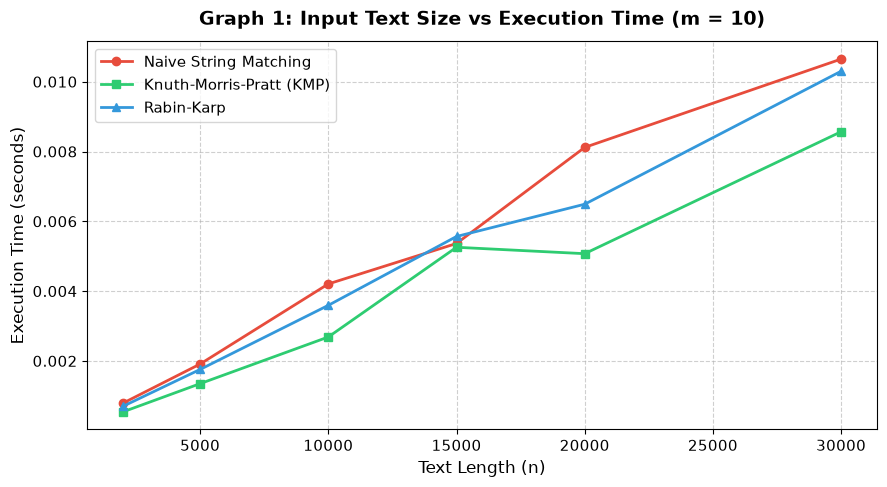

In [13]:
# Plot 1: Input Size vs Execution Time
plt.figure(figsize=(9, 5))
plt.plot(text_sizes, time_naive_n, marker='o', label='Naive String Matching', color='#e74c3c', linewidth=2)
plt.plot(text_sizes, time_kmp_n, marker='s', label='Knuth-Morris-Pratt (KMP)', color='#2ecc71', linewidth=2)
plt.plot(text_sizes, time_rk_n, marker='^', label='Rabin-Karp', color='#3498db', linewidth=2)

plt.title('Graph 1: Input Text Size vs Execution Time (m = 10)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Text Length (n)', fontsize=12)
plt.ylabel('Execution Time (seconds)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [14]:
# Benchmark 2: Pattern Length vs Execution Time
pattern_lengths = [5, 10, 25, 50, 75, 100, 150]
fixed_n = 20000
text_bench_fixed = generate_random_string(fixed_n)

time_naive_m = []
time_kmp_m = []
time_rk_m = []

for m in pattern_lengths:
    p_bench = generate_random_string(m)

    # Naive Timing
    t0 = time.perf_counter()
    naive_string_match(text_bench_fixed, p_bench)
    time_naive_m.append(time.perf_counter() - t0)

    # KMP Timing
    t0 = time.perf_counter()
    kmp_search(text_bench_fixed, p_bench)
    time_kmp_m.append(time.perf_counter() - t0)

    # Rabin-Karp Timing
    t0 = time.perf_counter()
    rabin_karp_search(text_bench_fixed, p_bench)
    time_rk_m.append(time.perf_counter() - t0)

print("Benchmark 2 completed!")

Benchmark 2 completed!


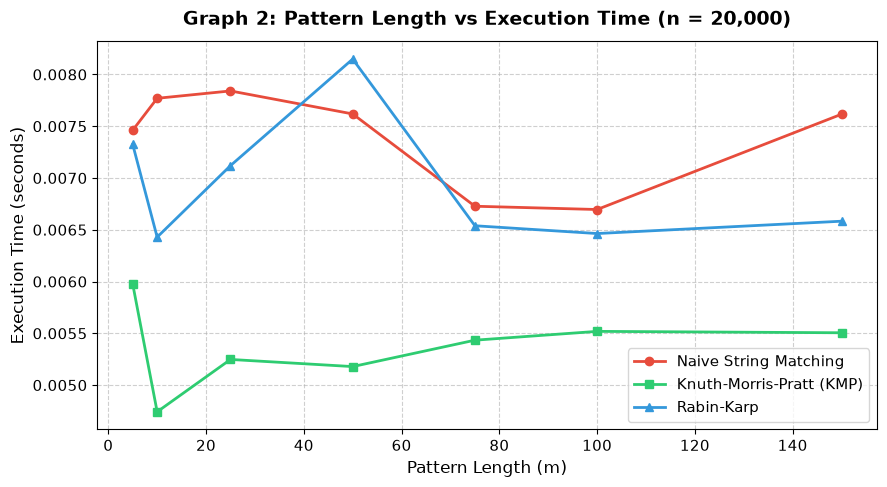

In [15]:
# Plot 2: Pattern Length vs Execution Time
plt.figure(figsize=(9, 5))
plt.plot(pattern_lengths, time_naive_m, marker='o', label='Naive String Matching', color='#e74c3c', linewidth=2)
plt.plot(pattern_lengths, time_kmp_m, marker='s', label='Knuth-Morris-Pratt (KMP)', color='#2ecc71', linewidth=2)
plt.plot(pattern_lengths, time_rk_m, marker='^', label='Rabin-Karp', color='#3498db', linewidth=2)

plt.title('Graph 2: Pattern Length vs Execution Time (n = 20,000)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Pattern Length (m)', fontsize=12)
plt.ylabel('Execution Time (seconds)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

In [16]:
# Benchmark 3: Input Size vs Number of Comparisons (Repetitive alphabet to show KMP efficiency)
comp_text_sizes = [1000, 2000, 4000, 6000, 8000, 10000]
pattern_comp = "AB" * 5  # Length m = 10

comps_naive = []
comps_kmp = []

for n in comp_text_sizes:
    # Binary alphabet 'A' and 'B' creates frequent prefix overlaps
    text_comp = generate_random_string(n, alphabet="AB")

    _, cn = naive_string_match(text_comp, pattern_comp)
    _, ck = kmp_search(text_comp, pattern_comp)

    comps_naive.append(cn)
    comps_kmp.append(ck)

print("Benchmark 3 completed!")

Benchmark 3 completed!


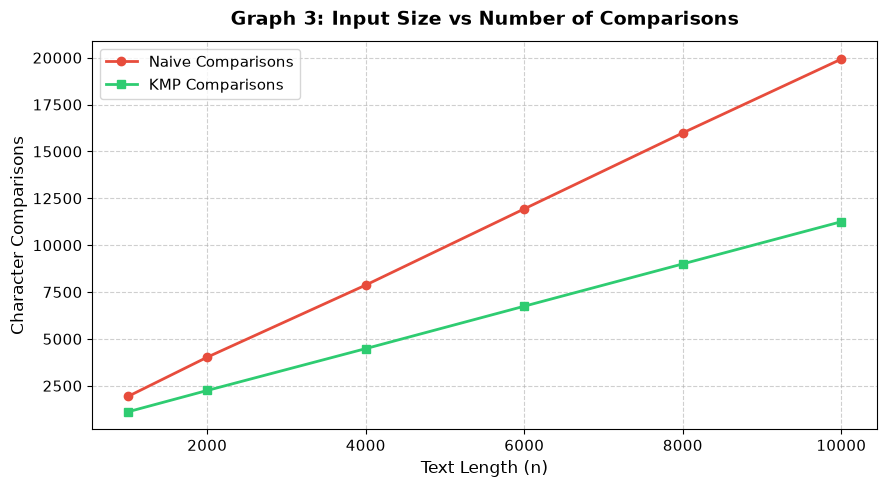

In [17]:
# Plot 3: Input Size vs Number of Comparisons
plt.figure(figsize=(9, 5))
plt.plot(comp_text_sizes, comps_naive, marker='o', label='Naive Comparisons', color='#e74c3c', linewidth=2)
plt.plot(comp_text_sizes, comps_kmp, marker='s', label='KMP Comparisons', color='#2ecc71', linewidth=2)

plt.title('Graph 3: Input Size vs Number of Comparisons', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Text Length (n)', fontsize=12)
plt.ylabel('Character Comparisons', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

---
## Summary & Experimental Conclusion

| Algorithm | Preprocessing Time | Matching Time | Space Complexity | Character Backtracking | Best Suited For |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Naive String Matching** | None ($0$) | $O((n - m + 1) \cdot m)$ | $O(1)$ | Yes | Short strings, large random alphabets |
| **Knuth–Morris–Pratt (KMP)** | $O(m)$ (LPS array) | $O(n)$ | $O(m)$ | No | Highly repetitive patterns, small alphabets |
| **Rabin–Karp** | $O(m)$ (Pattern hash) | Avg: $O(n + m)$, Worst: $O(nm)$ | $O(1)$ | No | Multiple pattern search, streaming data |

### Key Observations from Experiments:
1. **KMP vs Naive Comparisons**: In repetitive text strings (Graph 3), KMP performs substantially fewer comparisons than Naive because the LPS array shifts the pattern without re-examining previously matched characters.
2. **Execution Time Scaling**: Both KMP and Rabin-Karp maintain near-linear execution time with respect to text length $n$, while Naive suffers on repetitive text.
3. **Hash Collisions in Rabin-Karp**: A match in hash values only warrants a potential match. Choosing a large prime $q$ keeps spurious hits minimal, ensuring $O(n+m)$ performance.